# Phase 4: Statistical Evaluation in R

## Step 1: Environment Setup

In [ ]:
# Mounting Drive and enabling R cells (%%R) in this Python notebook via rpy2
from google.colab import drive
drive.mount('/content/drive')
%load_ext rpy2.ipython

Mounted at /content/drive


## Step 2: Installing R Packages

In [ ]:
%%R
# Installing the R packages for ROC analysis, data handling and plotting (only missing ones)
pkgs <- c('pROC', 'dplyr', 'tidyr', 'readr', 'ggplot2')
missing <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(missing)) install.packages(missing, quiet = TRUE)
invisible(lapply(pkgs, library, character.only = TRUE))
cat('Loaded:', pkgs, '\n')

Loaded: pROC dplyr tidyr readr ggplot2 


Type 'citation("pROC")' for a citation.

Attaching package: ‘pROC’

The following objects are masked from ‘package:stats’:

    cov, smooth, var


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



## Step 3: Testing the Workflow on the Baseline Models

In [ ]:
%%R
# Bootstrap 95% CIs for baseline AUROCs and a paired DeLong test (LogReg vs XGBoost) on the same test ECGs
RES <- '/content/drive/MyDrive/ecg-project/results'
set.seed(42)

b <- read_csv(file.path(RES, 'preds_test_baseline_binary.csv'), show_col_types = FALSE)
roc_lr  <- roc(b$y_true, b$p_LogReg,  levels = c(0, 1), direction = '<', quiet = TRUE)
roc_xgb <- roc(b$y_true, b$p_XGBoost, levels = c(0, 1), direction = '<', quiet = TRUE)

for (m in list(list('LogReg', roc_lr), list('XGBoost', roc_xgb))) {
  ci <- ci.auc(m[[2]], method = 'bootstrap', boot.n = 2000, progress = 'none')
  cat(sprintf('%-8s AUROC %.3f (95%% CI %.3f-%.3f)\n', m[[1]], ci[2], ci[1], ci[3]))
}
print(roc.test(roc_lr, roc_xgb, method = 'delong', paired = TRUE))

LogReg   AUROC 0.885 (95% CI 0.871-0.898)
XGBoost  AUROC 0.917 (95% CI 0.905-0.928)

	DeLong's test for two correlated ROC curves

data:  roc_lr and roc_xgb
Z = -6.9658, p-value = 3.265e-12
alternative hypothesis: true difference in AUC is not equal to 0
95 percent confidence interval:
 -0.04122341 -0.02311933
sample estimates:
AUC of roc1 AUC of roc2 
  0.8847646   0.9169359 



In addition: Warning messages:
1: In ci.auc.roc(m[[2]], method = "bootstrap", boot.n = 2000, progress = "none") :
  Progress bars are deprecated in pROC 1.19. Ignoring 'progress' argument
2: In ci.auc.roc(m[[2]], method = "bootstrap", boot.n = 2000, progress = "none") :
  Progress bars are deprecated in pROC 1.19. Ignoring 'progress' argument


## Step 4: Joining Predictions with Patient Metadata

In [ ]:
%%R
# Joining test predictions with patient metadata (age, sex, diagnostic classes) and define age bands
meta <- read_csv('/content/drive/MyDrive/ecg-project/data_processed/metadata.csv', show_col_types = FALSE)
test <- b %>%
  inner_join(select(meta, -abnormal), by = 'ecg_id') %>%
  mutate(age_band = cut(age, c(-Inf, 40, 60, 75, Inf), right = FALSE,
                        labels = c('<40', '40-59', '60-74', '75+')))
cat(nrow(test), 'test ECGs\n')
print(table(test$sex))
print(table(test$age_band))

2158 test ECGs

   F    M 
1048 1110 

  <40 40-59 60-74   75+ 
  284   639   706   529 


## Step 5: Operating-Point Metrics with Confidence Intervals

In [ ]:
%%R
# Sensitivity and specificity with bootstrap 95% CIs at each model's validation-chosen threshold, plus McNemar's test
thr <- read_csv(file.path(RES, 'baseline_binary_metrics.csv'), show_col_types = FALSE)
thr <- setNames(thr$Threshold, thr[[1]])

op_point <- function(y, p, t, B = 2000) {
  stat <- function(i) { pred <- p[i] >= t; c(Sensitivity = mean(pred[y[i] == 1]), Specificity = mean(!pred[y[i] == 0])) }
  est <- stat(seq_along(y))
  ci <- apply(replicate(B, stat(sample(length(y), replace = TRUE))), 1, quantile, c(0.025, 0.975))
  sprintf('%.3f (%.3f-%.3f)', est, ci[1, ], ci[2, ]) |> setNames(names(est))
}

set.seed(42)
for (m in c('LogReg', 'XGBoost')) {
  cat(m, ':', paste(names(op_point(test$y_true, test[[paste0('p_', m)]], thr[m])),
                    op_point(test$y_true, test[[paste0('p_', m)]], thr[m]), collapse = ' | '), '\n')
}

correct_lr  <- (test$p_LogReg  >= thr['LogReg'])  == test$y_true
correct_xgb <- (test$p_XGBoost >= thr['XGBoost']) == test$y_true
print(table(LogReg_correct = correct_lr, XGBoost_correct = correct_xgb))
print(mcnemar.test(table(correct_lr, correct_xgb)))

New names:
• `` -> `...1`
LogReg : Sensitivity 0.747 (0.724-0.773) | Specificity 0.882 (0.861-0.902) 
XGBoost : Sensitivity 0.794 (0.771-0.816) | Specificity 0.899 (0.879-0.918) 
              XGBoost_correct
LogReg_correct FALSE TRUE
         FALSE   263  160
         TRUE     86 1649

	McNemar's Chi-squared test with continuity correction

data:  table(correct_lr, correct_xgb)
McNemar's chi-squared = 21.663, df = 1, p-value = 3.251e-06



## Step 6: Subgroup Analysis and Forest Plot

# A tibble: 7 × 5
  group         n   auc    lo    hi
  <chr>     <int> <dbl> <dbl> <dbl>
1 Overall    2158 0.917 0.906 0.928
2 Male       1110 0.916 0.900 0.932
3 Female     1048 0.918 0.901 0.934
4 Age <40     284 0.775 0.711 0.840
5 Age 40-59   639 0.882 0.855 0.910
6 Age 60-74   706 0.905 0.884 0.927
7 Age 75+     529 0.950 0.931 0.969

Share of each abnormal class flagged as abnormal (XGBoost):
   MI  STTC    CD   HYP 
0.844 0.896 0.796 0.851 


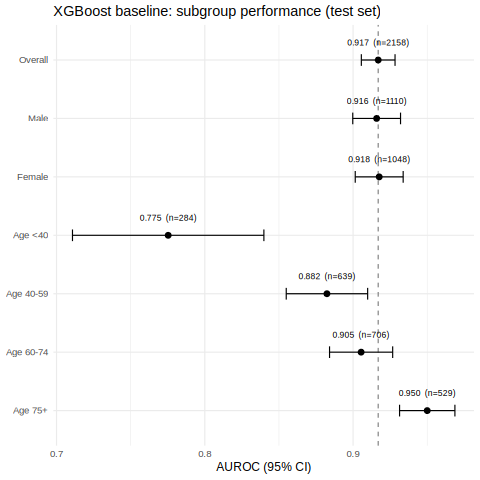

In [ ]:
%%R
# (6a): AUROC with 95% CI (DeLong) for sex and age subgroups, a forest plot, and detection rate per diagnostic class
subgroup_auc <- function(df, score) {
  groups <- list(Overall = rep(TRUE, nrow(df)), Male = df$sex == 'M', Female = df$sex == 'F')
  for (a in levels(df$age_band)) groups[[paste('Age', a)]] <- df$age_band == a
  bind_rows(lapply(names(groups), function(g) {
    d <- df[groups[[g]], ]
    ci <- ci.auc(roc(d$y_true, d[[score]], levels = c(0, 1), direction = '<', quiet = TRUE))
    tibble(group = g, n = nrow(d), auc = ci[2], lo = ci[1], hi = ci[3])
  }))
}

forest_plot <- function(sg, title, file) {
  sg$group <- factor(sg$group, levels = rev(sg$group))
  p <- ggplot(sg, aes(auc, group)) +
    geom_vline(xintercept = sg$auc[sg$group == 'Overall'], linetype = 2, colour = 'grey50') +
    geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.2, orientation = 'y') +
    geom_point(size = 2.5) +
    geom_text(aes(label = sprintf('%.3f  (n=%d)', auc, n)), nudge_y = 0.3, size = 3) +
    labs(x = 'AUROC (95% CI)', y = NULL, title = title) +
    theme_minimal(base_size = 12)
  ggsave(file.path(RES, 'figures', file), p, width = 7, height = 4.5, dpi = 150)
  print(p)
}

sg_xgb <- subgroup_auc(test, 'p_XGBoost')
print(sg_xgb, n = Inf)
forest_plot(sg_xgb, 'XGBoost baseline: subgroup performance (test set)', 'subgroups_xgboost.png')

detect <- sapply(c('MI', 'STTC', 'CD', 'HYP'), function(c) mean(test$p_XGBoost[test[[c]] == 1] >= thr['XGBoost']))
cat('\nShare of each abnormal class flagged as abnormal (XGBoost):\n'); print(round(detect, 3))

### Step 6b: Investigating the Age Gap

In [ ]:
%%R
# (6b): Is the weaker performance under 40 driven by false alarms or missed cases? Plus a formal test of the gap
test %>%
  group_by(age_band) %>%
  summarise(n = n(), abnormal_rate = mean(y_true),
            sensitivity = mean(p_XGBoost[y_true == 1] >= thr['XGBoost']),
            specificity = mean(p_XGBoost[y_true == 0] <  thr['XGBoost'])) %>%
  mutate(across(where(is.double), ~ round(.x, 3))) %>%
  print()

young <- test$age_band == '<40'
r_young <- roc(test$y_true[young],  test$p_XGBoost[young],  levels = c(0, 1), direction = '<', quiet = TRUE)
r_older <- roc(test$y_true[!young], test$p_XGBoost[!young], levels = c(0, 1), direction = '<', quiet = TRUE)
print(roc.test(r_young, r_older, method = 'delong', paired = FALSE))

# A tibble: 4 × 5
  age_band     n abnormal_rate sensitivity specificity
  <fct>    <int>         <dbl>       <dbl>       <dbl>
1 <40        284         0.232       0.303       0.927
2 40-59      639         0.415       0.698       0.898
3 60-74      706         0.643       0.806       0.889
4 75+        529         0.871       0.907       0.853

	DeLong's test for two ROC curves

data:  r_young and r_older
D = -4.3909, df = 301.77, p-value = 1.564e-05
alternative hypothesis: true difference in AUC is not equal to 0
sample estimates:
AUC of roc1 AUC of roc2 
  0.7752989   0.9222452 



## Step 6c: Which Conditions Are Missed Under 40?

In [ ]:
%%R
# Step 6c: Count abnormal ECGs under 40 per diagnostic class and the share the model missed
young_abn <- test %>%
  filter(age_band == '<40', y_true == 1) %>%
  mutate(missed = p_XGBoost < thr['XGBoost'])

cat('Abnormal ECGs under 40:', nrow(young_abn), '| missed:', sum(young_abn$missed), '\n\n')
sapply(c('MI', 'STTC', 'CD', 'HYP'), function(c) {
  idx <- young_abn[[c]] == 1
  c(n = sum(idx), missed = sum(young_abn$missed[idx]), miss_rate = round(mean(young_abn$missed[idx]), 2))
})

Abnormal ECGs under 40: 66 | missed: 46 

            MI STTC    CD  HYP
n         7.00 20.0 37.00 10.0
missed    2.00 10.0 30.00  5.0
miss_rate 0.29  0.5  0.81  0.5


## Step 7: Calibration

# A tibble: 2 × 4
  model   brier intercept slope
  <chr>   <dbl>     <dbl> <dbl>
1 LogReg  0.135     0.154 0.908
2 XGBoost 0.114     0.186 0.875


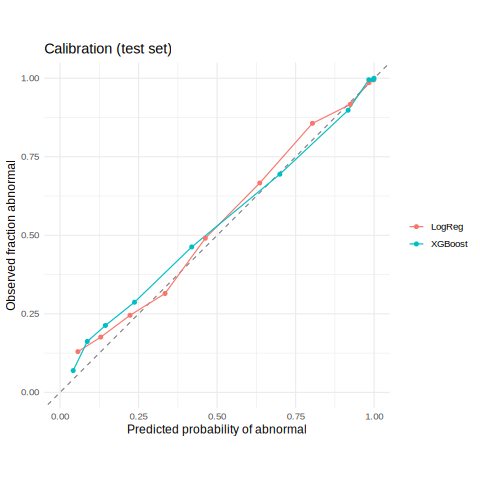

In [ ]:
%%R
# Calibration: Brier score, calibration intercept/slope, and a reliability curve (10 bins)
calibration <- function(y, p, model) {
  p <- pmin(pmax(p, 1e-6), 1 - 1e-6)
  fit <- glm(y ~ qlogis(p), family = binomial)
  bins <- tibble(y, p) %>% mutate(bin = ntile(p, 10)) %>%
    group_by(bin) %>% summarise(pred = mean(p), obs = mean(y), n = n(), .groups = 'drop')
  list(stats = tibble(model, brier = mean((p - y)^2), intercept = coef(fit)[1], slope = coef(fit)[2]),
       bins = mutate(bins, model = model))
}

cal <- lapply(c('LogReg', 'XGBoost'), function(m) calibration(test$y_true, test[[paste0('p_', m)]], m))
print(bind_rows(lapply(cal, `[[`, 'stats')) %>% mutate(across(where(is.numeric), ~ round(.x, 3))))

p <- ggplot(bind_rows(lapply(cal, `[[`, 'bins')), aes(pred, obs, colour = model)) +
  geom_abline(linetype = 2, colour = 'grey50') + geom_line() + geom_point() +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = 'Predicted probability of abnormal', y = 'Observed fraction abnormal',
       title = 'Calibration (test set)', colour = NULL) +
  theme_minimal(base_size = 12)
ggsave(file.path(RES, 'figures', 'calibration_baseline.png'), p, width = 6, height = 5, dpi = 150)
print(p)

## Step 8: Compare All Models (Task A)

In [ ]:
%%R
# AUROC with bootstrap 95% CIs for all four models, and pairwise DeLong tests (Holm-adjusted)
d <- read_csv(file.path(RES, 'preds_test_deep_binary.csv'), show_col_types = FALSE)
dt <- read_csv(file.path(RES, 'deep_thresholds.csv'), show_col_types = FALSE)
thr_all <- c(thr, CNN = dt$Threshold[dt[[1]] == 'cnn'], ResNet = dt$Threshold[dt[[1]] == 'resnet'])

all <- test %>% inner_join(select(d, ecg_id, p_cnn, p_resnet), by = 'ecg_id')
models <- c(LogReg = 'p_LogReg', XGBoost = 'p_XGBoost', CNN = 'p_cnn', ResNet = 'p_resnet')
rocs <- lapply(models, function(col) roc(all$y_true, all[[col]], levels = c(0, 1), direction = '<', quiet = TRUE))

set.seed(42)
auc_tab <- bind_rows(lapply(names(rocs), function(m) {
  ci <- ci.auc(rocs[[m]], method = 'bootstrap', boot.n = 2000)
  op <- op_point(all$y_true, all[[models[[m]]]], thr_all[m])
  tibble(model = m, AUROC = sprintf('%.3f (%.3f-%.3f)', ci[2], ci[1], ci[3]),
         Sensitivity = op['Sensitivity'], Specificity = op['Specificity'])
}))
print(auc_tab, width = Inf)

pairs <- list(c('ResNet', 'CNN'), c('ResNet', 'XGBoost'), c('CNN', 'XGBoost'))
delong <- bind_rows(lapply(pairs, function(pr) {
  t <- roc.test(rocs[[pr[1]]], rocs[[pr[2]]], method = 'delong', paired = TRUE)
  tibble(comparison = paste(pr, collapse = ' vs '),
         auc_diff = round(unname(t$estimate[1] - t$estimate[2]), 4), p = t$p.value)
})) %>% mutate(p_holm = p.adjust(p, 'holm'))
print(delong)
write_csv(delong, file.path(RES, 'delong_binary.csv'))

New names:
• `` -> `...1`
# A tibble: 4 × 4
  model   AUROC               Sensitivity         Specificity        
  <chr>   <chr>               <chr>               <chr>              
1 LogReg  0.885 (0.871-0.898) 0.747 (0.723-0.772) 0.882 (0.861-0.902)
2 XGBoost 0.917 (0.905-0.928) 0.794 (0.771-0.815) 0.899 (0.879-0.917)
3 CNN     0.944 (0.934-0.952) 0.819 (0.799-0.842) 0.918 (0.900-0.936)
4 ResNet  0.941 (0.931-0.950) 0.852 (0.832-0.873) 0.893 (0.872-0.911)
# A tibble: 3 × 4
  comparison        auc_diff        p   p_holm
  <chr>                <dbl>    <dbl>    <dbl>
1 ResNet vs CNN      -0.002  5.41e- 2 5.41e- 2
2 ResNet vs XGBoost   0.0241 6.10e-11 1.22e-10
3 CNN vs XGBoost      0.0261 4.53e-12 1.36e-11


## Step 9: Subgroups and the Age Gap Across Models

# A tibble: 21 × 6
   group         n   auc    lo    hi model  
   <fct>     <int> <dbl> <dbl> <dbl> <fct>  
 1 Overall    2158 0.917 0.906 0.928 XGBoost
 2 Male       1110 0.916 0.9   0.932 XGBoost
 3 Female     1048 0.918 0.901 0.934 XGBoost
 4 Age <40     284 0.775 0.711 0.84  XGBoost
 5 Age 40-59   639 0.882 0.855 0.91  XGBoost
 6 Age 60-74   706 0.905 0.884 0.927 XGBoost
 7 Age 75+     529 0.95  0.931 0.969 XGBoost
 8 Overall    2158 0.943 0.934 0.952 CNN    
 9 Male       1110 0.95  0.938 0.962 CNN    
10 Female     1048 0.937 0.923 0.95  CNN    
11 Age <40     284 0.861 0.807 0.914 CNN    
12 Age 40-59   639 0.914 0.891 0.937 CNN    
13 Age 60-74   706 0.936 0.92  0.952 CNN    
14 Age 75+     529 0.954 0.934 0.974 CNN    
15 Overall    2158 0.941 0.932 0.95  ResNet 
16 Male       1110 0.948 0.936 0.96  ResNet 
17 Female     1048 0.935 0.921 0.948 ResNet 
18 Age <40     284 0.852 0.799 0.904 ResNet 
19 Age 40-59   639 0.917 0.894 0.939 ResNet 
20 Age 60-74   706 0.93  0.913 0.948

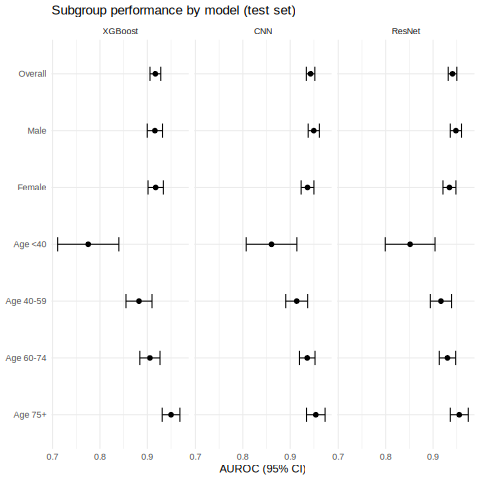

In [ ]:
%%R
# Subgroup AUROCs for XGBoost, CNN and ResNet side by side, plus sensitivity under 40 (overall and for conduction disturbances)
sg_all <- bind_rows(lapply(c('XGBoost', 'CNN', 'ResNet'), function(m) mutate(subgroup_auc(all, models[[m]]), model = m)))
sg_all$group <- factor(sg_all$group, levels = rev(unique(sg_all$group)))
sg_all$model <- factor(sg_all$model, levels = c('XGBoost', 'CNN', 'ResNet'))
print(sg_all %>% mutate(across(c(auc, lo, hi), ~ round(.x, 3))), n = Inf)

p <- ggplot(sg_all, aes(auc, group)) +
  geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.25, orientation = 'y') +
  geom_point(size = 2) +
  facet_wrap(~ model, nrow = 1) +
  labs(x = 'AUROC (95% CI)', y = NULL, title = 'Subgroup performance by model (test set)') +
  theme_minimal(base_size = 11)
ggsave(file.path(RES, 'figures', 'subgroups_all_models.png'), p, width = 10, height = 4.5, dpi = 150)
print(p)

young <- all %>% filter(age_band == '<40', y_true == 1)
print(round(sapply(c('XGBoost', 'CNN', 'ResNet'), function(m) c(
  sens_young_all = mean(young[[models[[m]]]] >= thr_all[m]),
  sens_young_CD  = mean(young[[models[[m]]]][young$CD == 1] >= thr_all[m]))), 3))

## Step 10: Calibration Across Models

# A tibble: 4 × 4
  model   brier intercept slope
  <chr>   <dbl>     <dbl> <dbl>
1 LogReg  0.135     0.154 0.908
2 XGBoost 0.114     0.186 0.875
3 CNN     0.1       0.657 0.93 
4 ResNet  0.1       0.534 0.952


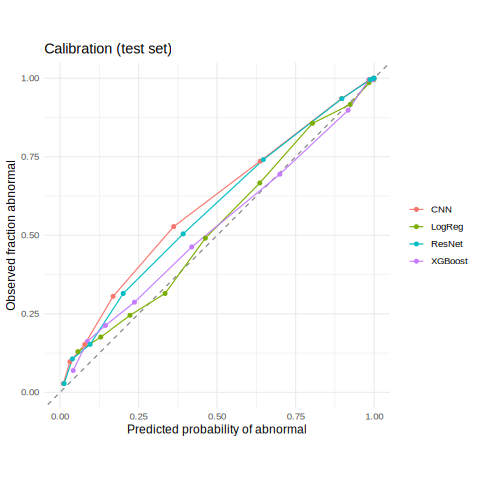

In [ ]:
%%R
# Brier score, calibration slope and reliability curves for all four models
cal_all <- lapply(names(models), function(m) calibration(all$y_true, all[[models[[m]]]], m))
print(bind_rows(lapply(cal_all, `[[`, 'stats')) %>% mutate(across(where(is.numeric), ~ round(.x, 3))))

p <- ggplot(bind_rows(lapply(cal_all, `[[`, 'bins')), aes(pred, obs, colour = model)) +
  geom_abline(linetype = 2, colour = 'grey50') + geom_line() + geom_point() +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = 'Predicted probability of abnormal', y = 'Observed fraction abnormal',
       title = 'Calibration (test set)', colour = NULL) +
  theme_minimal(base_size = 12)
ggsave(file.path(RES, 'figures', 'calibration_all_models.png'), p, width = 6, height = 5, dpi = 150)
print(p)

Step 11: Recaliberation

# A tibble: 4 × 4
  model             brier intercept slope
  <chr>             <dbl>     <dbl> <dbl>
1 CNN               0.1       0.657 0.93 
2 ResNet            0.1       0.534 0.952
3 CNN_calibrated    0.094     0.106 1.01 
4 ResNet_calibrated 0.096     0.131 0.997


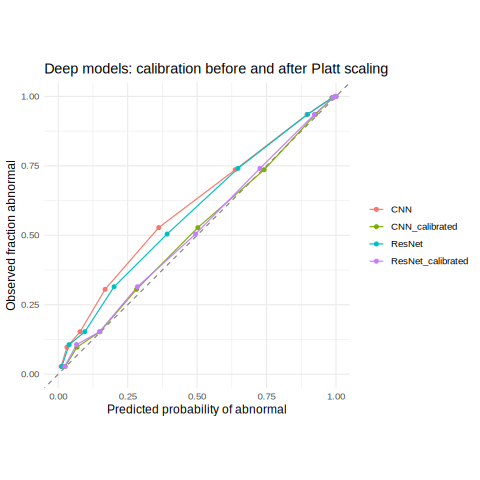

In [ ]:
%%R
# Calibration of the deep models before and after Platt scaling
d2 <- read_csv(file.path(RES, 'preds_test_deep_binary.csv'), show_col_types = FALSE)
allc <- all %>% left_join(select(d2, ecg_id, p_cnn_cal, p_resnet_cal), by = 'ecg_id')
cols <- c(CNN = 'p_cnn', ResNet = 'p_resnet', CNN_calibrated = 'p_cnn_cal', ResNet_calibrated = 'p_resnet_cal')
cal_c <- lapply(names(cols), function(m) calibration(allc$y_true, allc[[cols[[m]]]], m))
print(bind_rows(lapply(cal_c, `[[`, 'stats')) %>% mutate(across(where(is.numeric), ~ round(.x, 3))))

p <- ggplot(bind_rows(lapply(cal_c, `[[`, 'bins')), aes(pred, obs, colour = model)) +
  geom_abline(linetype = 2, colour = 'grey50') + geom_line() + geom_point() +
  coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(x = 'Predicted probability of abnormal', y = 'Observed fraction abnormal',
       title = 'Deep models: calibration before and after Platt scaling', colour = NULL) +
  theme_minimal(base_size = 12)
ggsave(file.path(RES, 'figures', 'calibration_platt.png'), p, width = 6.5, height = 5, dpi = 150)
print(p)